In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings("ignore")

In [2]:
landslide_df = pd.read_excel(r"C:\Users\SM\Projects_ML2\landslide_points_all_values.xls")
non_landslide_df = pd.read_excel(r"C:\Users\SM\Projects_ML2\non_landslide_all_values.xls")

In [3]:
# %pip install xlrd

In [4]:
landslide_df["landslide"] = 1
non_landslide_df["landslide"] = 0

df = pd.concat(
    [landslide_df, non_landslide_df],
    ignore_index=True
)

print("Combined dataset:", df.shape)
display(df.head())

Combined dataset: (608, 18)


,OBJECTID,X_cord,Y_cord,Slope___,Aspect___,Curvature,Elevation_,TWI,Rain,River_Dist,Road_Dist,LULC,Geology,Soil_Type,Landslide,landslide,OID,Elevation
0,1.0,434306.0,2974310.0,32.363400,127.333000,0.116704,320.0,4.52595,1455.239990,290.300995,1430.189941,Rangeland,Middle Siwalik,Dystric Regosols,1,1,NaN,NaN
1,2.0,434278.0,2974160.0,19.634501,137.910995,-0.466815,316.0,5.50595,1455.040039,309.640991,1560.359985,Rangeland,Middle Siwalik,Dystric Regosols,1,1,NaN,NaN
2,3.0,435641.0,2975310.0,24.106600,103.240997,-1.400440,344.0,4.87397,1448.390015,727.335999,1150.729980,Forest,Upper Siwalik,Dystric Regosols,1,1,NaN,NaN
3,4.0,445886.0,2978720.0,30.701599,229.667007,0.816925,384.0,4.59103,1399.630005,158.828995,831.270020,Rangeland,Lower Siwalik,Dystric Regosols,1,1,NaN,NaN
4,5.0,447011.0,2976400.0,25.318399,239.035995,-0.233407,439.0,5.73456,1379.900024,216.154007,796.322998,Forest,Lower Siwalik,Dystric Regosols,1,1,NaN,NaN


In [5]:
df.head()

,OBJECTID,X_cord,Y_cord,Slope___,Aspect___,Curvature,Elevation_,TWI,Rain,River_Dist,Road_Dist,LULC,Geology,Soil_Type,Landslide,landslide,OID,Elevation
0,1.0,434306.0,2974310.0,32.363400,127.333000,0.116704,320.0,4.52595,1455.239990,290.300995,1430.189941,Rangeland,Middle Siwalik,Dystric Regosols,1,1,NaN,NaN
1,2.0,434278.0,2974160.0,19.634501,137.910995,-0.466815,316.0,5.50595,1455.040039,309.640991,1560.359985,Rangeland,Middle Siwalik,Dystric Regosols,1,1,NaN,NaN
2,3.0,435641.0,2975310.0,24.106600,103.240997,-1.400440,344.0,4.87397,1448.390015,727.335999,1150.729980,Forest,Upper Siwalik,Dystric Regosols,1,1,NaN,NaN
3,4.0,445886.0,2978720.0,30.701599,229.667007,0.816925,384.0,4.59103,1399.630005,158.828995,831.270020,Rangeland,Lower Siwalik,Dystric Regosols,1,1,NaN,NaN
4,5.0,447011.0,2976400.0,25.318399,239.035995,-0.233407,439.0,5.73456,1379.900024,216.154007,796.322998,Forest,Lower Siwalik,Dystric Regosols,1,1,NaN,NaN


In [6]:
df.tail()

,OBJECTID,X_cord,Y_cord,Slope___,Aspect___,Curvature,Elevation_,TWI,Rain,River_Dist,Road_Dist,LULC,Geology,Soil_Type,Landslide,landslide,OID,Elevation
603,NaN,450338.46875,2972290.5,7.096683,185.906143,0.000000,NaN,5.460122,1355.726196,456.053223,1704.790527,Forest,Lower Siwalik,Dystric Regosols,0,0,396.0,419.0
604,NaN,500746.12500,2957038.5,1.729529,8.130101,0.233407,NaN,10.768549,1446.814087,41.409454,1655.908691,Agricultural Land,Recent,Fluvisols,0,0,397.0,95.0
605,NaN,454563.71875,2995915.0,25.701851,27.474432,-1.050333,NaN,10.457045,1552.184570,115.315941,514.642944,Forest,Sarung Khola Formation,Eutric Cambisols,0,0,398.0,702.0
606,NaN,440664.21875,2987476.0,20.829763,225.000000,-3.384405,NaN,7.387555,1492.925049,795.730347,1259.588989,Forest,Lower Siwalik,Dystric Regosols,0,0,399.0,489.0
607,NaN,487775.31250,2955458.5,10.906205,282.804260,0.466815,NaN,5.023369,1468.164795,117.324493,1294.453369,Forest,Lower Siwalik,Dystric Regosols,0,0,400.0,211.0


In [7]:
df.shape

(608, 18)

In [8]:
df.columns

Index(['OBJECTID', 'X_cord', 'Y_cord', 'Slope___', 'Aspect___', 'Curvature',
       'Elevation_', 'TWI', 'Rain', 'River_Dist', 'Road_Dist', 'LULC',
       'Geology', 'Soil_Type', 'Landslide', 'landslide', 'OID', 'Elevation'],
      dtype='object')

In [9]:
df.dtypes

OBJECTID      float64
X_cord        float64
Y_cord        float64
Slope___      float64
Aspect___     float64
Curvature     float64
Elevation_    float64
TWI           float64
Rain          float64
River_Dist    float64
Road_Dist     float64
LULC           object
Geology        object
Soil_Type      object
Landslide       int64
landslide       int64
OID           float64
Elevation     float64
dtype: object

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 608 entries, 0 to 607
Data columns (total 18 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   OBJECTID    208 non-null    float64
 1   X_cord      608 non-null    float64
 2   Y_cord      608 non-null    float64
 3   Slope___    607 non-null    float64
 4   Aspect___   607 non-null    float64
 5   Curvature   608 non-null    float64
 6   Elevation_  208 non-null    float64
 7   TWI         607 non-null    float64
 8   Rain        608 non-null    float64
 9   River_Dist  608 non-null    float64
 10  Road_Dist   608 non-null    float64
 11  LULC        608 non-null    object 
 12  Geology     608 non-null    object 
 13  Soil_Type   608 non-null    object 
 14  Landslide   608 non-null    int64  
 15  landslide   608 non-null    int64  
 16  OID         400 non-null    float64
 17  Elevation   400 non-null    float64
dtypes: float64(13), int64(2), object(3)
memory usage: 85.6+ KB


In [11]:
df.describe()

,OBJECTID,X_cord,Y_cord,Slope___,Aspect___,Curvature,Elevation_,TWI,Rain,River_Dist,Road_Dist,Landslide,landslide,OID,Elevation
count,208.000000,608.000000,6.080000e+02,607.000000,607.000000,608.000000,208.000000,607.000000,608.000000,608.000000,608.000000,608.000000,608.000000,400.000000,400.000000
mean,104.500000,469643.637798,2.977072e+06,22.218851,172.864118,-0.085032,745.091346,6.143299,1467.134307,466.163862,1104.933101,0.342105,0.342105,200.500000,543.710000
std,60.188592,23148.642534,1.249920e+04,13.639949,90.404582,1.617815,381.819818,2.081030,59.802241,362.723321,907.137267,0.474805,0.474805,115.614301,422.178912
min,1.000000,421365.000000,2.953350e+06,0.000000,-1.000000,-17.388800,172.000000,3.281830,1353.984985,0.000000,0.000000,0.000000,0.000000,1.000000,92.000000
25%,52.750000,452157.195312,2.968636e+06,9.810937,112.789364,-0.700222,446.500000,4.765615,1423.262085,190.138248,440.804413,0.000000,0.000000,100.750000,205.750000
50%,104.500000,467766.500000,2.974582e+06,23.321100,168.690063,-0.116704,649.500000,5.692127,1460.675293,384.118439,911.312073,0.000000,0.000000,200.500000,405.000000
75%,156.250000,487930.562500,2.986635e+06,33.222193,236.360466,0.583518,994.750000,6.807109,1508.435272,699.228882,1524.499664,1.000000,1.000000,300.250000,774.500000
max,208.000000,516075.000000,3.005149e+06,60.589500,358.531189,7.469030,2064.000000,16.981260,1612.186279,1811.989990,5291.829590,1.000000,1.000000,400.000000,1970.000000


In [12]:
df.isnull().sum()

OBJECTID      400
X_cord          0
Y_cord          0
Slope___        1
Aspect___       1
Curvature       0
Elevation_    400
TWI             1
Rain            0
River_Dist      0
Road_Dist       0
LULC            0
Geology         0
Soil_Type       0
Landslide       0
landslide       0
OID           208
Elevation     208
dtype: int64

In [13]:
# Merge Elevation_ into Elevation
df["Elevation"] = df["Elevation"].combine_first(df["Elevation_"])

# Drop the old elevation column
df.drop(columns=["Elevation_"], inplace=True)

# Check missing values
print(df[["Elevation"]].isnull().sum())

Elevation    0
dtype: int64


In [14]:
print(pd.crosstab(df["Landslide"], df["landslide"]))  # Run before dropping Landslide

landslide    0    1
Landslide          
0          400    0
1            0  208


In [15]:
df.drop(
    columns=["OBJECTID", "OID", "Landslide"],
    errors="ignore",
    inplace=True
)

print(df.columns.tolist())

['X_cord', 'Y_cord', 'Slope___', 'Aspect___', 'Curvature', 'TWI', 'Rain', 'River_Dist', 'Road_Dist', 'LULC', 'Geology', 'Soil_Type', 'landslide', 'Elevation']


In [16]:
# Fill numeric missing values with median
numeric_fill_cols = ["Slope___", "TWI"]

for col in numeric_fill_cols:
    df[col] = df[col].fillna(df[col].median())

print(df.isnull().sum())

X_cord        0
Y_cord        0
Slope___      0
Aspect___     1
Curvature     0
TWI           0
Rain          0
River_Dist    0
Road_Dist     0
LULC          0
Geology       0
Soil_Type     0
landslide     0
Elevation     0
dtype: int64


What about Aspect___?    
Aspect is circular: 359° and 1° are close, not far apart. For its one missing value, use a circular mean rather than an ordinary median:

In [17]:
aspect_rad = np.deg2rad(df["Aspect___"].dropna())

mean_sin = np.sin(aspect_rad).mean()
mean_cos = np.cos(aspect_rad).mean()

circular_mean = np.rad2deg(
    np.arctan2(mean_sin, mean_cos)
) % 360

df["Aspect___"] = df["Aspect___"].fillna(circular_mean)

print(df[["Slope___", "Aspect___", "TWI"]].isnull().sum())

Slope___     0
Aspect___    0
TWI          0
dtype: int64


In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
sns.set_theme(style="whitegrid")

### 1. Landslide vs. Non-Landslide Distribution
Shows how many samples belong to each class.

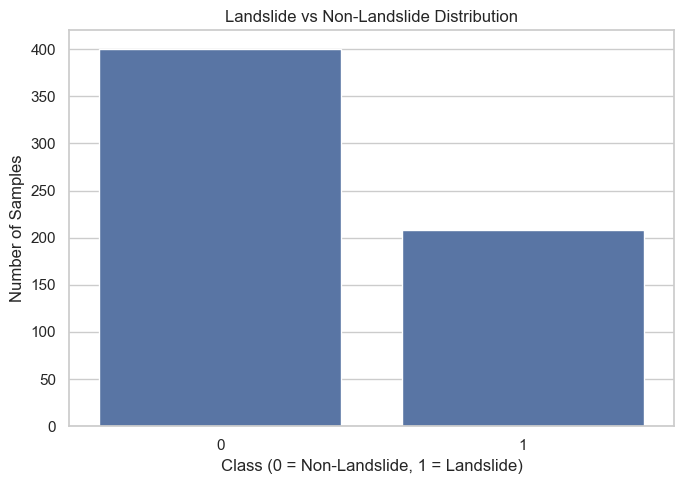

In [20]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="landslide")

plt.title("Landslide vs Non-Landslide Distribution")
plt.xlabel("Class (0 = Non-Landslide, 1 = Landslide)")
plt.ylabel("Number of Samples")

plt.tight_layout()
plt.show()

### 2. Slope Distribution by Landslide Class
Helps you compare slope values for landslide and non-landslide locations.

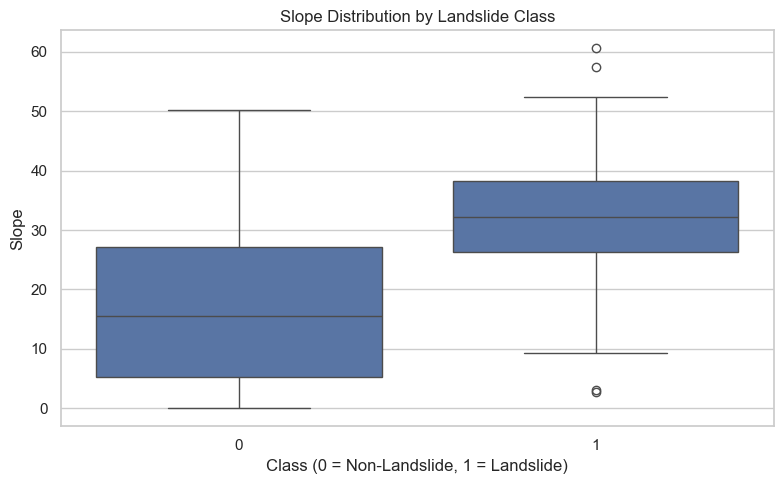

In [21]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="landslide", y="Slope___")

plt.title("Slope Distribution by Landslide Class")
plt.xlabel("Class (0 = Non-Landslide, 1 = Landslide)")
plt.ylabel("Slope")

plt.tight_layout()
plt.show()

### 3. Rainfall Distribution by Landslide Class
Shows how rainfall values differ between the two classes.

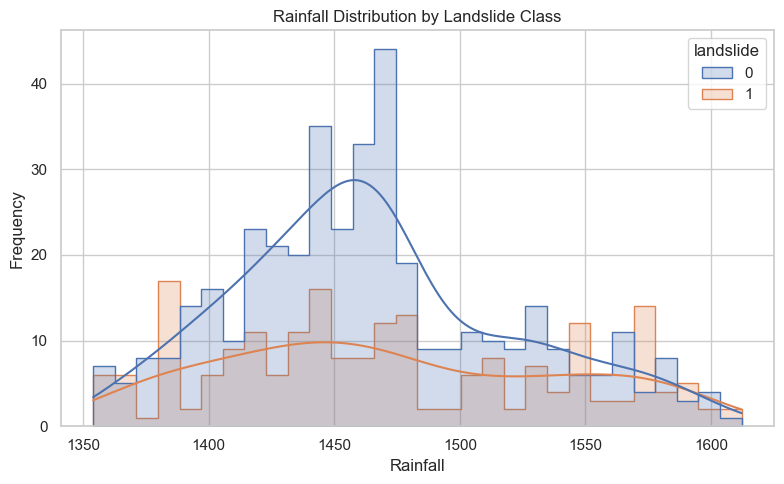

In [22]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Rain",
    hue="landslide",
    bins=30,
    kde=True,
    element="step"
)

plt.title("Rainfall Distribution by Landslide Class")
plt.xlabel("Rainfall")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### 4. Correlation Heatmap
Shows relationships between numerical features such as slope, elevation, rainfall, and distance from rivers and roads.

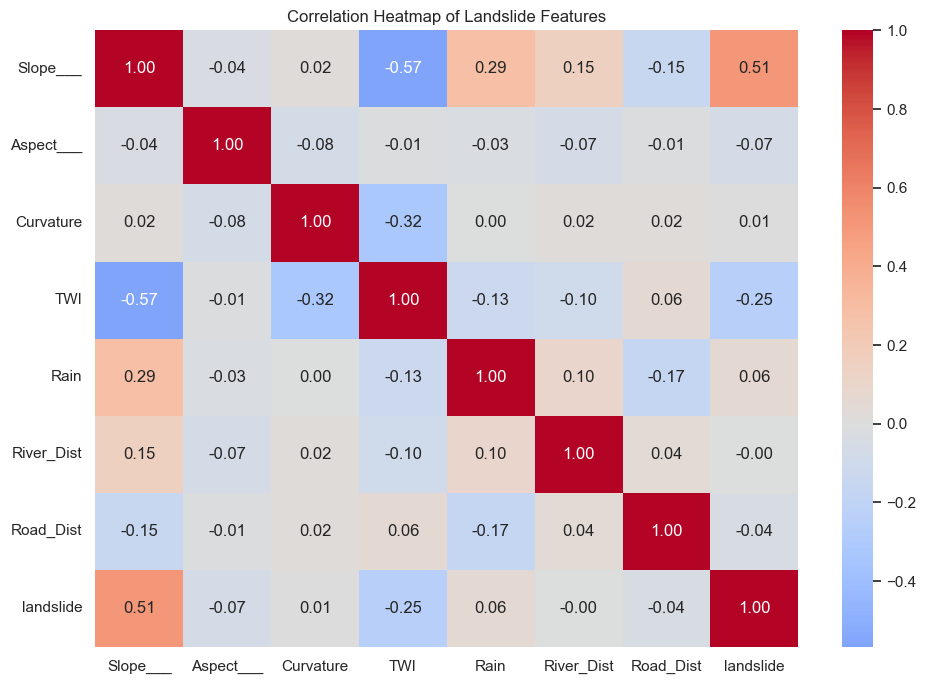

In [23]:
numeric_cols = [
    "Slope___",
    "Aspect___",
    "Curvature",
    "TWI",
    "Rain",
    "River_Dist",
    "Road_Dist",
    "landslide"
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap of Landslide Features")

plt.tight_layout()
plt.show()

### 5. Landslide Counts by Land Use (LULC)
Shows which land-use categories have more landslide samples.

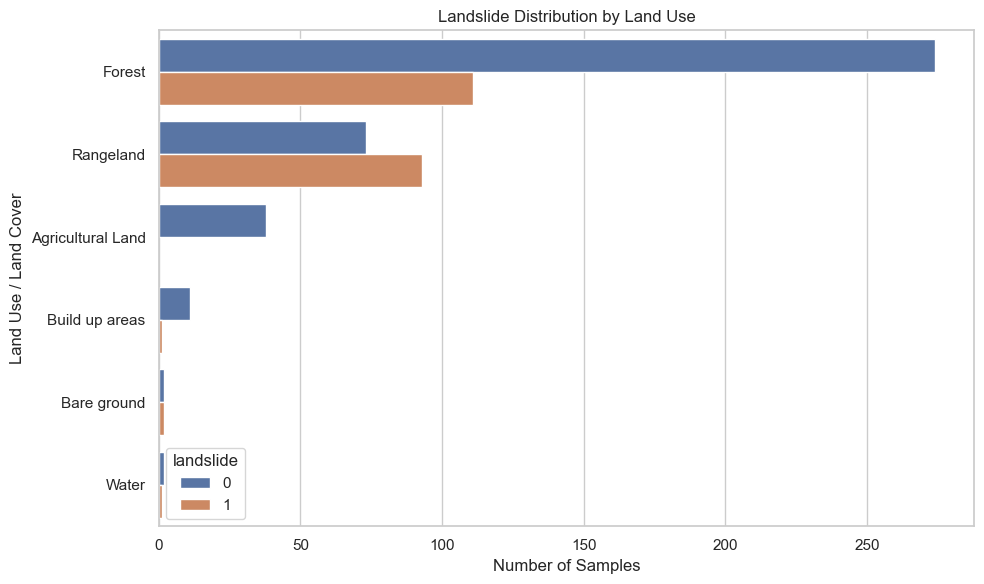

In [24]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y="LULC",
    hue="landslide",
    order=df["LULC"].value_counts().index
)

plt.title("Landslide Distribution by Land Use")
plt.xlabel("Number of Samples")
plt.ylabel("Land Use / Land Cover")

plt.tight_layout()
plt.show()

In [25]:
numeric = df.select_dtypes(include = 'number')
for col in numeric:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    outliers = outliers.shape[0]
    print(f"{col}:{outliers}")

X_cord:0
Y_cord:0
Slope___:0
Aspect___:0
Curvature:50
TWI:40
Rain:0
River_Dist:10
Road_Dist:27
landslide:0
Elevation:7


In [26]:
df["landslide"].value_counts()

landslide
0    400
1    208
Name: count, dtype: int64

In [27]:
x = df.drop('landslide',axis=1)
y = df[['landslide']]

In [28]:
print("X shape:", x.shape)
print("y shape:", y.shape)

X shape: (608, 13)
y shape: (608, 1)


In [29]:
numerical_cols = y.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_cols = y.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)

Numerical columns: ['landslide']
Categorical columns: []


In [30]:
X = x.drop(columns=['X_cord', 'Y_cord'], errors='ignore')

numerical_cols = x.select_dtypes(
    include=['number']
).columns.tolist()

categorical_cols = x.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

In [31]:
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

In [32]:
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

In [33]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (486, 11)
X_test: (122, 11)
y_train: (486, 1)
y_test: (122, 1)


In [37]:
# Target column
y = df["landslide"]

# Remove the target from input features
x = df.drop(columns=["landslide"])

# Keep coordinates separately for later mapping
coordinates = df[["X_cord", "Y_cord"]].copy()

# Remove coordinates from the model features for now
X = x.drop(columns=["X_cord", "Y_cord"], errors="ignore")

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Features shape: (608, 11)
Target shape: (608,)

Target distribution:
landslide
0    400
1    208
Name: count, dtype: int64


In [38]:
numerical_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)

Numerical columns: ['Slope___', 'Aspect___', 'Curvature', 'TWI', 'Rain', 'River_Dist', 'Road_Dist', 'Elevation']
Categorical columns: ['LULC', 'Geology', 'Soil_Type']


In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (486, 11)
Testing features: (122, 11)
Training target: (486,)
Testing target: (122,)


In [41]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


Accuracy: 0.8115

Classification Report:
               precision    recall  f1-score   support

Non-Landslide       0.84      0.89      0.86        80
    Landslide       0.76      0.67      0.71        42

     accuracy                           0.81       122
    macro avg       0.80      0.78      0.78       122
 weighted avg       0.81      0.81      0.81       122



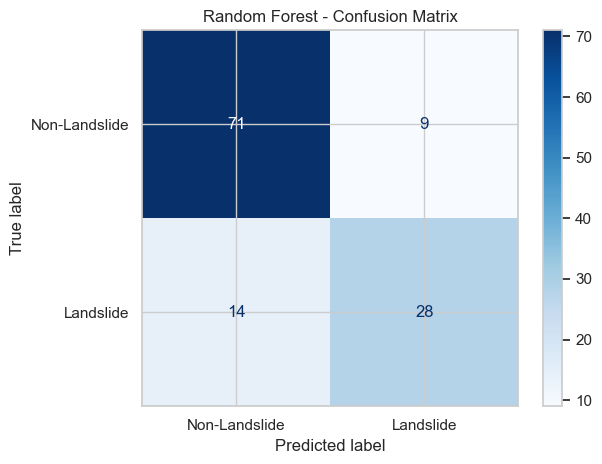

In [42]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred_rf = rf_model.predict(X_test)

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_rf), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Non-Landslide", "Landslide"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred_rf)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Landslide", "Landslide"]
).plot(cmap="Blues")

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

In [43]:
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score, recall_score
import pandas as pd

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        eval_metric="logloss",
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Landslide Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "Landslide F1": f1_score(
            y_test, predictions, zero_division=0
        )
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results)
display(results_df.sort_values("Landslide F1", ascending=False))

,Model,Accuracy,Landslide Recall,Landslide F1
2,XGBoost,0.868852,0.809524,0.809524
0,Logistic Regression,0.754098,0.904762,0.716981
1,Random Forest,0.811475,0.666667,0.708861


,Feature,Importance
0,num__Slope___,0.208061
7,num__Elevation,0.123466
1,num__Aspect___,0.120396
3,num__TWI,0.098311
2,num__Curvature,0.083459
4,num__Rain,0.075965
6,num__Road_Dist,0.071877
5,num__River_Dist,0.063348
12,cat__LULC_Rangeland,0.022995
11,cat__LULC_Forest,0.017509


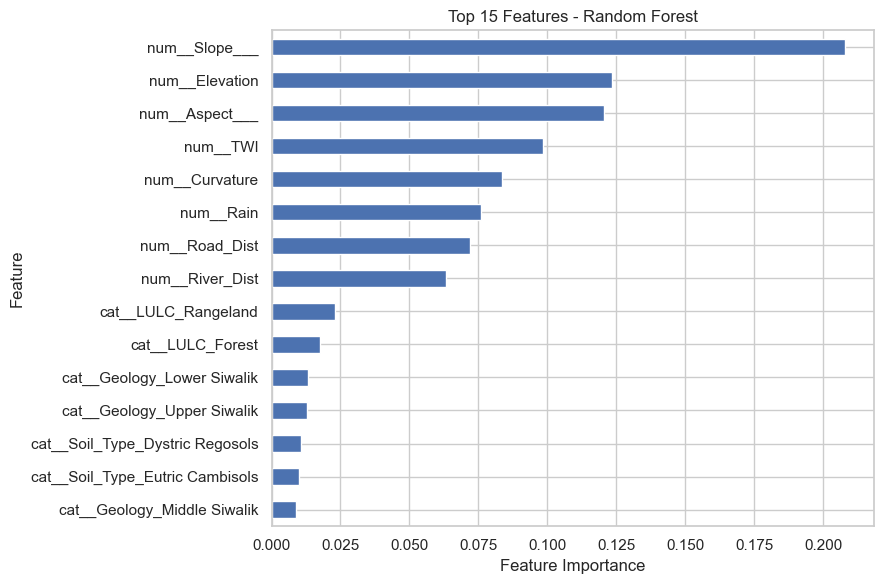

In [44]:
rf_pipeline = trained_models["Random Forest"]

feature_names = (
    rf_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    rf_pipeline
    .named_steps["classifier"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

importance_df.head(15).sort_values(
    "Importance"
).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    figsize=(9, 6)
)

plt.title("Top 15 Features - Random Forest")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

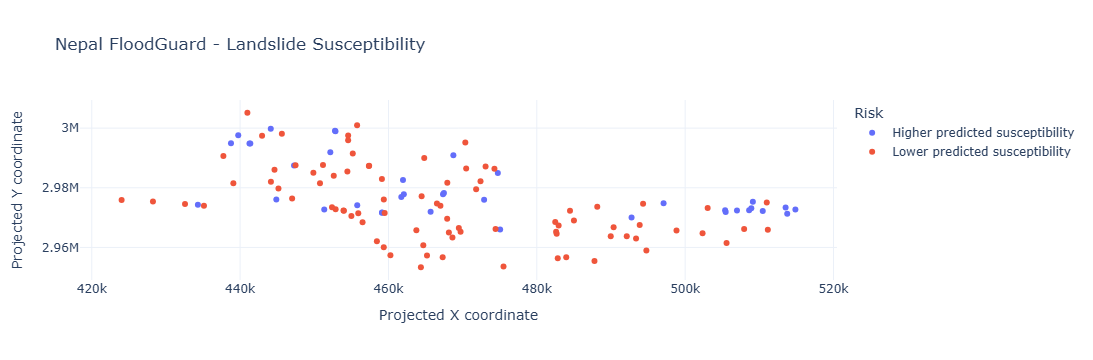

In [45]:
import plotly.express as px

map_df = coordinates.loc[X_test.index].copy()

map_df["Actual"] = y_test
map_df["Predicted"] = y_pred_rf

map_df["Risk"] = map_df["Predicted"].map({
    0: "Lower predicted susceptibility",
    1: "Higher predicted susceptibility"
})

fig = px.scatter(
    map_df,
    x="X_cord",
    y="Y_cord",
    color="Risk",
    hover_data=["Actual", "Predicted"],
    title="Nepal FloodGuard - Landslide Susceptibility",
    labels={
        "X_cord": "Projected X coordinate",
        "Y_cord": "Projected Y coordinate"
    }
)

fig.update_layout(template="plotly_white")
fig.show()

In [46]:
import joblib
import os

os.makedirs("floodguard_models", exist_ok=True)

final_model = trained_models["Random Forest"]

joblib.dump(
    final_model,
    "floodguard_models/landslide_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


,Model,Accuracy,Landslide Recall,Landslide F1
2,XGBoost,0.868852,0.809524,0.809524
0,Logistic Regression,0.754098,0.904762,0.716981
1,Random Forest,0.811475,0.666667,0.708861


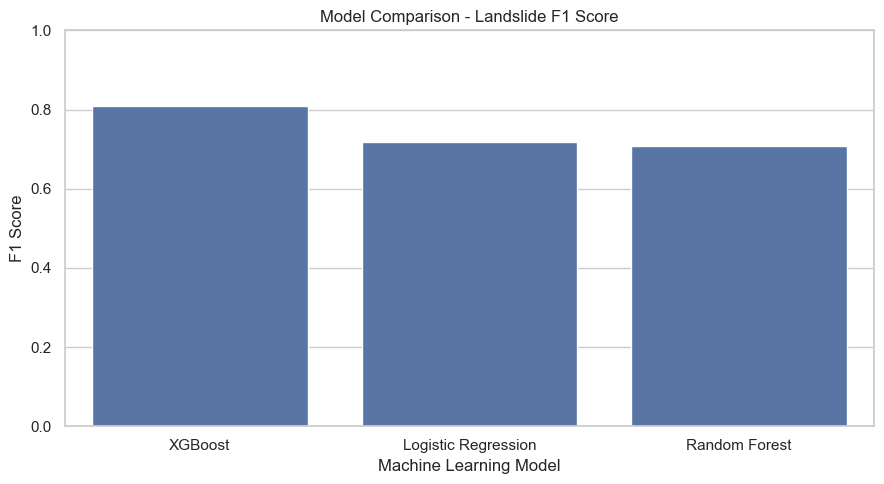

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

comparison = results_df.sort_values(
    "Landslide F1", ascending=False
)

display(comparison)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=comparison,
    x="Model",
    y="Landslide F1"
)

plt.title("Model Comparison - Landslide F1 Score")
plt.ylim(0, 1)
plt.ylabel("F1 Score")
plt.xlabel("Machine Learning Model")
plt.tight_layout()
plt.show()

In [48]:

import os
import joblib

# Create a folder for the model and supporting files
os.makedirs("floodguard_models", exist_ok=True)

# Save the complete trained pipeline, including preprocessing
joblib.dump(rf_model, "floodguard_models/landslide_model.pkl")

# Save the original training columns and example values for the app
joblib.dump(X_train, "floodguard_models/X_train_reference.pkl")

print("Model and input reference saved successfully!")
print("Number of input features:", X_train.shape[1])
print("Input columns:", X_train.columns.tolist())


Model and input reference saved successfully!
Number of input features: 11
Input columns: ['Slope___', 'Aspect___', 'Curvature', 'TWI', 'Rain', 'River_Dist', 'Road_Dist', 'LULC', 'Geology', 'Soil_Type', 'Elevation']
